<a href="https://colab.research.google.com/github/ayandeshmukh75-hue/CodeAlpha_Iris_Flower_Classification/blob/main/CodeAlpha_Iris_Flower_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:

import pandas as pd
import os
from google.colab import files

file_path = "/content/Iris.csv"

if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    print("Previously uploaded dataset found!")
else:
    uploaded = files.upload()

    if uploaded:
        file_name = next(iter(uploaded))
        df = pd.read_csv(file_name)
        print("Dataset uploaded successfully!")
    else:
        raise ValueError("Please select the Iris.csv file.")

print("Dataset shape:", df.shape)
display(df.head())

Saving Iris.csv to Iris.csv
Dataset uploaded successfully!
Dataset shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSpecies Count:")
print(df["Species"].value_counts())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Missing Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Species Count:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Statistical Summary:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [ ]:

# Graph 1: Species distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Species")
plt.title("Iris Species Distribution")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Graph 2: Petal length vs petal width
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="PetalLengthCm",
    y="PetalWidthCm",
    hue="Species",
    s=70
)
plt.title("Petal Length vs Petal Width")
plt.tight_layout()
plt.show()

# Graph 3: Measurement comparison
measurement_columns = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

df.boxplot(
    column=measurement_columns,
    by="Species",
    figsize=(12, 6)
)
plt.suptitle("Measurements by Iris Species")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

<Figure size 700x400 with 0 Axes>

In [ ]:

# Input features
X = df[
    [
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalLengthCm",
        "PetalWidthCm"
    ]
]

# Target variable
y = df["Species"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of input features:", X_train.shape[1])

Training records: 120
Testing records: 30
Number of input features: 4


In [ ]:

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

print("\nFeature Importance:")
for feature, importance in zip(
    X.columns,
    model.feature_importances_
):
    print(f"{feature}: {importance:.4f}")

Model training completed successfully!

Feature Importance:
SepalLengthCm: 0.1163
SepalWidthCm: 0.0150
PetalLengthCm: 0.4315
PetalWidthCm: 0.4372


Model Accuracy: 90.00%

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.82      0.90      0.86        10
 Iris-virginica       0.89      0.80      0.84        10

       accuracy                           0.90        30
      macro avg       0.90      0.90      0.90        30
   weighted avg       0.90      0.90      0.90        30



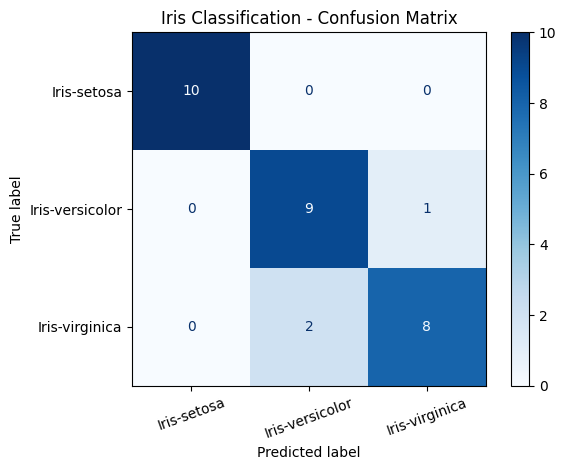

In [ ]:

# Predict test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Iris Classification - Confusion Matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:

print("Enter flower measurements in centimetres:")

sepal_length = float(input("Sepal Length: "))
sepal_width = float(input("Sepal Width: "))
petal_length = float(input("Petal Length: "))
petal_width = float(input("Petal Width: "))

new_flower = pd.DataFrame(
    [[
        sepal_length,
        sepal_width,
        petal_length,
        petal_width
    ]],
    columns=[
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalLengthCm",
        "PetalWidthCm"
    ]
)

prediction = model.predict(new_flower)[0]
probabilities = model.predict_proba(new_flower)[0]

print("\nPredicted Iris Species:", prediction)

print("\nPrediction probabilities:")
for species, probability in zip(
    model.classes_,
    probabilities
):
    print(f"{species}: {probability * 100:.2f}%")

Enter flower measurements in centimetres:
Sepal Length: 5.1
Sepal Width: 3.5
Petal Length: 1.4
Petal Width: 0.2

Predicted Iris Species: Iris-setosa

Prediction probabilities:
Iris-setosa: 100.00%
Iris-versicolor: 0.00%
Iris-virginica: 0.00%
